# Fintech topic modeling: 8,017 URL-verified articles

This notebook runs LDA and BERTopic on the **same** 8,017 gold-positive URLs from `fintech_classification/gold_labels.csv`, joined to `df_clean_final.csv` by exact `url`. Input text is `title + snippet + raw_article`. Results, figures, and diagnostics are retained as notebook outputs. Temporary checkpoints live outside the project in `~/.cache/fintech_topic_8017`; the runner removes them after successful execution.

**Design decisions.** No outcome labels enter either unsupervised model. Underthesea segments Vietnamese words once; those segments feed LDA and BERTopic's vectorizer. The embedding model receives the unsegmented article text. We compare topic counts, coherence, diversity, outlier share, and seed stability; no single metric establishes topical validity. Representative documents are included for human interpretation. The model's custom code is pinned and loaded with `trust_remote_code=True`; the installed Transformers 5 runtime needs a documented compatibility repair to its nonpersistent position buffers and attention-mask method.

**Primary documentation:** [model card](https://huggingface.co/dangvantuan/vietnamese-document-embedding), [Sentence Transformers encode](https://www.sbert.net/docs/package_reference/sentence_transformer/model.html), [BERTopic parameters](https://maartengr.github.io/BERTopic/getting_started/parameter%20tuning/parametertuning.html), [BERTopic visualizations](https://maartengr.github.io/BERTopic/getting_started/visualization/visualization.html), [Underthesea tokenizer](https://underthesea.readthedocs.io/en/latest/api.html), [Gensim LDA](https://radimrehurek.com/gensim/auto_examples/tutorials/run_lda.html), [Gensim coherence](https://radimrehurek.com/gensim/models/coherencemodel.html), [pyLDAvis](https://pyldavis.readthedocs.io/en/stable/modules/API.html).

In [1]:
from pathlib import Path
import os, re, json, time, gc, warnings, types, hashlib, pickle
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, HTML
from collections import Counter
from scipy.optimize import linear_sum_assignment
from sklearn.metrics.pairwise import cosine_similarity
ROOT = Path('/home/hanna/Documents/HUST/NCKH_Fintech_cô')
TMP = Path.home()/'.cache/fintech_topic_8017'; TMP.mkdir(parents=True,exist_ok=True)
SEEDS = [42, 123, 456]
MODEL_ID = 'dangvantuan/vietnamese-document-embedding'
MODEL_REVISION = '6fa4e2f8ed2d33120b0f4442cc81f8f973c3f56b'
CONFIG = {'embedding': {'model': MODEL_ID, 'device': 'cpu', 'batch_size': 4, 'normalize_embeddings': True, 'save_format': 'npy', 'checkpoint_every': 500, 'max_seq_length': 'model_default'}, 'umap': {'n_neighbors':[15,30], 'n_components':5, 'min_dist':0.0, 'metric':'cosine', 'low_memory':True, 'random_state':42, 'n_jobs':1}, 'hdbscan': {'min_cluster_size':[15,30,50], 'min_samples':[5,10], 'metric':'euclidean', 'cluster_selection_method':'eom', 'prediction_data':False, 'core_dist_n_jobs':1}, 'vectorizer': {'tokenizer':'underthesea', 'ngram_range':[1,2], 'min_df':2, 'max_features':30000, 'stopwords':'vietnamese_custom'}, 'ctfidf':{'reduce_frequent_words':True}, 'lda':{'num_topics':[5,10,15,20,25,30], 'alpha':'auto', 'eta':'auto', 'passes':10, 'iterations':100, 'chunksize':200, 'random_state':42, 'dictionary':{'no_below':5,'no_above':0.5,'keep_n':30000}}}
display(CONFIG)

{'embedding': {'model': 'dangvantuan/vietnamese-document-embedding',
  'device': 'cpu',
  'batch_size': 4,
  'normalize_embeddings': True,
  'save_format': 'npy',
  'checkpoint_every': 500,
  'max_seq_length': 'model_default'},
 'umap': {'n_neighbors': [15, 30],
  'n_components': 5,
  'min_dist': 0.0,
  'metric': 'cosine',
  'low_memory': True,
  'random_state': 42,
  'n_jobs': 1},
 'hdbscan': {'min_cluster_size': [15, 30, 50],
  'min_samples': [5, 10],
  'metric': 'euclidean',
  'cluster_selection_method': 'eom',
  'prediction_data': False,
  'core_dist_n_jobs': 1},
 'vectorizer': {'tokenizer': 'underthesea',
  'ngram_range': [1, 2],
  'min_df': 2,
  'max_features': 30000,
  'stopwords': 'vietnamese_custom'},
 'ctfidf': {'reduce_frequent_words': True},
 'lda': {'num_topics': [5, 10, 15, 20, 25, 30],
  'alpha': 'auto',
  'eta': 'auto',
  'passes': 10,
  'iterations': 100,
  'chunksize': 200,
  'random_state': 42,
  'dictionary': {'no_below': 5, 'no_above': 0.5, 'keep_n': 30000}}}

In [2]:
gold = pd.read_csv(ROOT/'fintech_classification/gold_labels.csv', encoding='utf-8-sig', dtype={'url':str,'gold_label':int})
positive = gold.loc[gold.gold_label.eq(1),'url']
assert len(positive)==8017 and positive.is_unique
fields = ['url','title','snippet','raw_article','pub_date']
wanted=set(positive)
source = pd.concat((chunk.loc[chunk.url.isin(wanted)] for chunk in pd.read_csv(ROOT/'df_clean_final.csv', encoding='utf-8-sig', usecols=fields, dtype=str, keep_default_na=False, chunksize=5000)), ignore_index=True)
assert source.url.is_unique
articles = source.set_index('url').loc[positive.tolist(),fields[1:]].reset_index()
del source; gc.collect()
for field in ['title','snippet','raw_article']:
    articles[field] = articles[field].fillna('').astype(str).str.strip()
articles['text'] = articles[['title','snippet','raw_article']].agg('\n'.join, axis=1)
articles['pub_date_parsed'] = pd.to_datetime(articles.pub_date, errors='coerce', utc=True, format='mixed')
hash_state=hashlib.sha256()
for url,text in zip(articles.url,articles.text):
    hash_state.update(url.encode('utf-8'));hash_state.update(b'\0');hash_state.update(text.encode('utf-8'));hash_state.update(b'\0')
CORPUS_SHA=hash_state.hexdigest()
assert len(articles)==8017 and articles.url.is_unique and articles.text.str.strip().ne('').all()
print('Articles',len(articles),'missing publication dates',articles.pub_date_parsed.isna().sum())
display(articles[['url','title','pub_date']].head(3))

Articles 8017 missing publication dates 0


,url,title,pub_date
0,https://cafef.vn/04-ly-do-nen-mo-the-tin-dung-...,04 lý do nên mở thẻ tín dụng Techcombank online,2023-10-28T08:00:00
1,https://cafef.vn/09-san-pham-cong-nghe-thong-t...,09 sản phẩm công nghệ thông tin của BIDV đạt g...,2023-04-29T08:00:00
2,https://cafef.vn/1-giao-vien-khai-vay-nong-tre...,1 giáo viên khai vay nóng trên mạng dính lãi s...,2019-10-27T21:56:21


## 1. Shared Vietnamese preprocessing

Underthesea segments phrases into underscore-joined tokens. The custom stopword list removes common function/reporting words while retaining finance/technology terms. We use the same token stream for LDA and BERTopic's c-TF-IDF vocabulary. Coherence uses a fixed 1,200-document reference sample, including adjacent bigrams, for computational feasibility; this sample is identical for both methods. Its uncertainty should be considered when scores are close.

In [3]:
from underthesea import word_tokenize
STOPWORDS = set(['và', 'là', 'của', 'cho', 'với', 'các', 'những', 'một', 'này', 'đó', 'trong', 'trên', 'dưới', 'từ', 'vào', 'ra', 'theo', 'khi', 'thì', 'đã', 'đang', 'sẽ', 'được', 'bị', 'có', 'cũng', 'như', 'để', 'vì', 'bởi', 'nên', 'rằng', 'về', 'tại', 'sau', 'trước', 'giữa', 'rất', 'hơn', 'nhất', 'đều', 'nhiều', 'ít', 'mỗi', 'mọi', 'hoặc', 'hay', 'nhưng', 'mà', 'nếu', 'do', 'qua', 'tới', 'đến', 'bởi', 'vì', 'tuy', 'nhiên', 'đồng', 'thời', 'ngoài', 'ra', 'bên', 'cạnh', 'mặt', 'khác', 'đối', 'với', 'liên', 'quan', 'cho', 'biết', 'cho', 'hay', 'cho', 'rằng', 'người', 'việc', 'thời', 'gian', 'năm', 'tháng', 'ngày', 'hôm', 'nay', 'hiện', 'nay', 'mới', 'vừa', 'tiếp', 'tục', 'thông', 'tin', 'báo', 'cáo', 'bài', 'viết', 'nội', 'dung', 'công', 'ty', 'doanh', 'nghiệp', 'thị', 'trường', 'việt', 'nam', 'hà', 'nội', 'thành', 'phố', 'nước', 'quốc', 'gia', 'ông', 'bà', 'anh', 'chị', 'họ', 'chúng', 'tôi', 'bạn', 'theo', 'đó', 'cụ', 'thể', 'đặc', 'biệt', 'đáng', 'chú', 'ý', 'lĩnh', 'vực', 'hoạt', 'động', 'phát', 'triển', 'thực', 'hiện', 'triển', 'khai', 'xây', 'dựng', 'đưa', 'ra', 'cho', 'thấy', 'cho', 'rằng', 'nhấn', 'mạnh', 'nhận', 'định', 'đánh', 'giá', 'chia', 'sẻ', 'khẳng', 'định'])
PRESERVE = set('fintech blockchain bitcoin crypto insurtech regtech ngân_hàng thanh_toán ví_điện_tử tài_chính tín_dụng cho_vay bảo_hiểm chứng_khoán công_nghệ'.split())
STOPWORDS -= PRESERVE
TOKEN_RE = re.compile(r'(?u)^[\w]+(?:_[\w]+)*$')
def tokenize(text):
    return [t for t in word_tokenize(text.lower(), format='text').split() if TOKEN_RE.fullmatch(t) and len(t)>1 and t not in STOPWORDS]
import pickle
TOKEN_CACHE=TMP/'tokens.pkl'
t0=time.time()
if TOKEN_CACHE.exists():
    with TOKEN_CACHE.open('rb') as f: cache=pickle.load(f)
    if cache.get('corpus_sha')==CORPUS_SHA and cache.get('stopwords')==sorted(STOPWORDS):
        tokens=cache['tokens']
    else:
        TOKEN_CACHE.unlink()
if not TOKEN_CACHE.exists():
    tokens=[tokenize(t) for t in articles.text]
    with TOKEN_CACHE.open('wb') as f: pickle.dump({'corpus_sha':CORPUS_SHA,'stopwords':sorted(STOPWORDS),'tokens':tokens},f,protocol=pickle.HIGHEST_PROTOCOL)
assert len(tokens)==8017 and min(map(len,tokens))>0
segmented=[' '.join(t) for t in tokens]
print('Tokenization minutes',round((time.time()-t0)/60,2),'median tokens',int(np.median(list(map(len,tokens)))))
display(tokens[0][:50])

Tokenization minutes 0.02 median tokens 420


['04',
 'lý_do',
 'mở',
 'thẻ_tín_dụng',
 'techcombank',
 'online',
 'thuận_tiện',
 'khách_hàng',
 'quá_trình',
 'đăng_ký',
 'sử_dụng',
 'techcombank',
 'cho_phép',
 'khách_hàng',
 'mở',
 'tín_dụng',
 'online',
 'thông_qua',
 'techcombank',
 'mobile',
 'chỉ',
 'phút',
 'thao_tác',
 'tcb',
 'thực_hiện',
 'online',
 'không',
 'cần',
 'quầy',
 'thông_thường',
 'khách_hàng',
 'cần',
 '15',
 'phút',
 '45',
 'phút',
 'quầy',
 'giao_dịch',
 'đăng_ký',
 'mở',
 'thẻ_tín_dụng',
 'chưa',
 'kể',
 'thời_gian',
 'di_chuyển',
 'tiết_kiệm',
 'thời_gian',
 'tăng',
 'trải_nghiệm',
 'dùng']

In [4]:
from gensim.corpora import Dictionary
from gensim.models import LdaModel, CoherenceModel
from sklearn.feature_extraction.text import CountVectorizer
reference_idx=np.random.default_rng(42).choice(len(tokens),size=min(1200,len(tokens)),replace=False)
def with_bigrams(seq):
    return seq + [seq[i]+' '+seq[i+1] for i in range(len(seq)-1)]
reference=[with_bigrams(tokens[i]) for i in reference_idx]
reference_dictionary=Dictionary(reference)
dictionary=Dictionary(tokens)
dictionary.filter_extremes(no_below=5,no_above=0.5,keep_n=30000)
corpus=[dictionary.doc2bow(t) for t in tokens]
print('LDA vocabulary',len(dictionary),'reference documents',len(reference),'nonempty bags',sum(bool(c) for c in corpus))
assert all(corpus)
def topic_diversity(topic_words):
    return len(set(w for topic in topic_words for w in topic))/(sum(map(len,topic_words)) or 1)
def coherence_scores(topic_words):
    scores={}
    for metric in ('c_v','c_npmi'):
        try:
            scores[metric]=float(CoherenceModel(topics=topic_words,texts=reference,dictionary=reference_dictionary,coherence=metric,topn=10,processes=1).get_coherence())
        except Exception as exc:
            warnings.warn(f'{metric} failed: {exc}')
            scores[metric]=np.nan
    return scores
def stability(a,b):
    # Hungarian maximum matching of top-word Jaccard sets; unmatched topics receive zero.
    if not a or not b: return np.nan
    sim=np.array([[len(set(x)&set(y))/len(set(x)|set(y)) for y in b] for x in a])
    row,col=linear_sum_assignment(-sim)
    return float(sim[row,col].sum()/max(len(a),len(b)))


LDA vocabulary 12236 reference documents 1200 nonempty bags 8017


## 2. LDA grid and stability

The six `K` values use identical tokenization and dictionary. `alpha='auto'` and `eta='auto'` are Gensim's learned asymmetric priors. We select the largest finite **c_v** score, breaking ties toward fewer topics, then rerun only that K with seeds 123 and 456 for stability. Reported stability is Hungarian-matched top-10-word Jaccard, with unmatched topics scored zero.

In [5]:
lda_rows=[]; lda_models={}; lda_words={}
for k in [5,10,15,20,25,30]:
    start=time.time()
    checkpoint=TMP/f'lda_k{k}_seed42.pkl'
    if checkpoint.exists():
        with checkpoint.open('rb') as f: payload=pickle.load(f)
        assert payload['corpus_sha']==CORPUS_SHA and payload['config']==CONFIG['lda']
        model=payload['model']; words=payload['words']; elapsed=payload['minutes']
        print('LDA restored',k,flush=True)
    else:
        model=LdaModel(corpus=corpus,id2word=dictionary,num_topics=k,alpha='auto',eta='auto',passes=10,iterations=100,chunksize=200,random_state=42,eval_every=None)
        words=[[w for w,_ in model.show_topic(i,topn=10)] for i in range(k)]
        elapsed=(time.time()-start)/60
        tmp=checkpoint.with_suffix('.partial')
        with tmp.open('wb') as f:pickle.dump({'corpus_sha':CORPUS_SHA,'config':CONFIG['lda'],'model':model,'words':words,'minutes':elapsed},f,protocol=pickle.HIGHEST_PROTOCOL)
        tmp.replace(checkpoint)
        print('LDA fitted',k,'topics in',round(elapsed,2),'minutes',flush=True)
    lda_rows.append({'num_topics':k,'topic_diversity':topic_diversity(words),'minutes':elapsed})
    lda_models[k]=model;lda_words[k]=words
all_lda_words=[topic for k in [5,10,15,20,25,30] for topic in lda_words[k]]
for metric in ('c_v','c_npmi'):
    checkpoint=TMP/f'lda_coherence_{metric}.json'
    if checkpoint.exists():
        payload=json.loads(checkpoint.read_text())
        assert payload['corpus_sha']==CORPUS_SHA
        per_topic=payload['per_topic']
    else:
        per_topic=CoherenceModel(topics=all_lda_words,texts=reference,dictionary=reference_dictionary,coherence=metric,topn=10,processes=1).get_coherence_per_topic()
        checkpoint.write_text(json.dumps({'corpus_sha':CORPUS_SHA,'per_topic':[float(x) for x in per_topic]}))
    offset=0
    for row in lda_rows:
        k=row['num_topics'];row[metric]=float(np.mean(per_topic[offset:offset+k]));offset+=k
    print('Coherence completed',metric,flush=True)
lda_scores=pd.DataFrame(lda_rows).sort_values('num_topics')
assert lda_scores.c_v.notna().any(), 'No valid LDA coherence scores'
best_k=int(lda_scores.sort_values(['c_v','num_topics'],ascending=[False,True]).iloc[0].num_topics)
seed_words={42:lda_words[best_k]}
for seed in [123,456]:
    checkpoint=TMP/f'lda_k{best_k}_seed{seed}_words.json'
    if checkpoint.exists():
        payload=json.loads(checkpoint.read_text());assert payload['corpus_sha']==CORPUS_SHA
        seed_words[seed]=payload['words']
    else:
        m=LdaModel(corpus=corpus,id2word=dictionary,num_topics=best_k,alpha='auto',eta='auto',passes=10,iterations=100,chunksize=200,random_state=seed,eval_every=None)
        seed_words[seed]=[[w for w,_ in m.show_topic(i,topn=10)] for i in range(best_k)]
        checkpoint.write_text(json.dumps({'corpus_sha':CORPUS_SHA,'words':seed_words[seed]}))
        del m;gc.collect()
    print('LDA stability fitted seed',seed,flush=True)
lda_stability=pd.DataFrame([{'seed_a':a,'seed_b':b,'matched_jaccard':stability(seed_words[a],seed_words[b])} for a,b in [(42,123),(42,456),(123,456)]])
display(lda_scores,lda_stability)
print('Selected LDA K',best_k)

LDA restored 5


LDA restored 10


LDA restored 15


LDA restored 20


LDA restored 25


LDA restored 30


... (3 outputs left out)

LDA stability fitted seed 456


,num_topics,topic_diversity,minutes,c_v,c_npmi
0,5,0.920000,0.985273,0.746400,0.133782
1,10,0.880000,1.128976,0.776455,0.162655
2,15,0.793333,1.291845,0.766710,0.157955
3,20,0.805000,1.321529,0.774708,0.161031
4,25,0.764000,1.456255,0.745406,0.139837
5,30,0.803333,1.538286,0.754989,0.150059


,seed_a,seed_b,matched_jaccard
0,42,123,0.438507
1,42,456,0.429961
2,123,456,0.402510


Selected LDA K 10


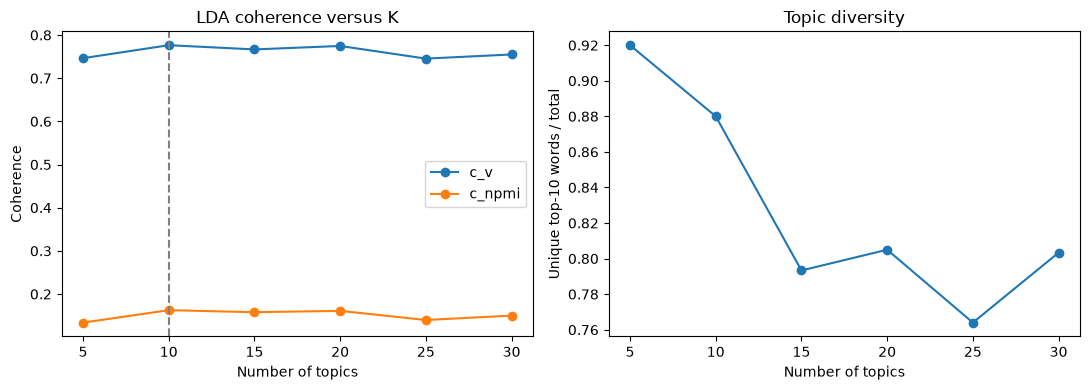

,topic,top_words,top_weight
0,0,"ứng_dụng, dùng, giúp, dữ_liệu, thiết_bị, bảo_m...",0.033485
1,1,"lừa_đảo, tài_khoản, đối_tượng, mạng, công_an, ...",0.036681
2,2,"vay, quy_định, rủi_ro, công_ty, tín_dụng, vốn,...",0.041937
3,3,"thanh_toán, dùng, tiền_mặt, thẻ, tài_khoản, ví...",0.092313
4,4,"thuế, bộ, hóa, cơ_quan, điện_tử, thương_mại_đi...",0.034876
5,5,"doanh_nghiệp, chuyển_đổi, khoa_học, kinh_tế, n...",0.026513
6,6,"thẻ, mua_sắm, ưu_đãi, thẻ_tín_dụng, vib, chươn...",0.025888
7,7,"công_ty, đầu_tư, trung_quốc, bán, sàn, mình, l...",0.016780
8,8,"tăng, bảo_hiểm, tỷ, tăng_trưởng, đạt, so, thị_...",0.025474
9,9,"bitcoin, usd, điện_tử, thị_trường, tăng, mức, ...",0.035782


In [6]:
fig,axs=plt.subplots(1,2,figsize=(11,4))
for col in ['c_v','c_npmi']:
    axs[0].plot(lda_scores.num_topics,lda_scores[col],marker='o',label=col)
axs[0].axvline(best_k,color='gray',ls='--');axs[0].set(xlabel='Number of topics',ylabel='Coherence',title='LDA coherence versus K');axs[0].legend()
axs[1].plot(lda_scores.num_topics,lda_scores.topic_diversity,marker='o');axs[1].set(xlabel='Number of topics',ylabel='Unique top-10 words / total',title='Topic diversity')
plt.tight_layout();display(fig);plt.close(fig)
lda_topic_table=pd.DataFrame([{'topic':i,'top_words':', '.join(w),'top_weight':float(lda_models[best_k].show_topic(i,topn=1)[0][1])} for i,w in enumerate(lda_words[best_k])])
display(lda_topic_table)

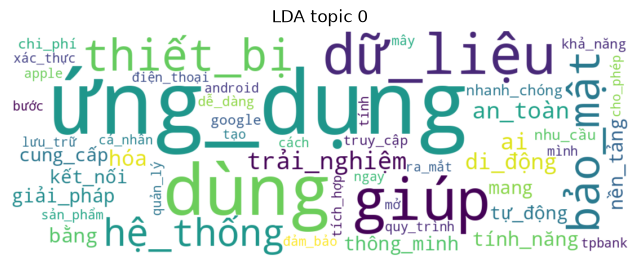

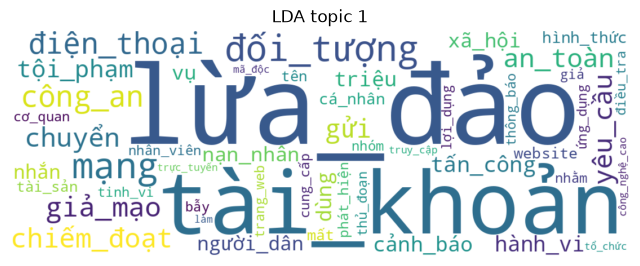

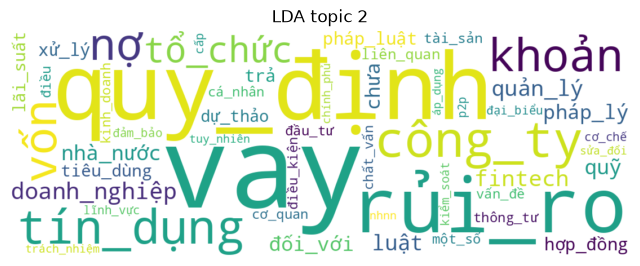

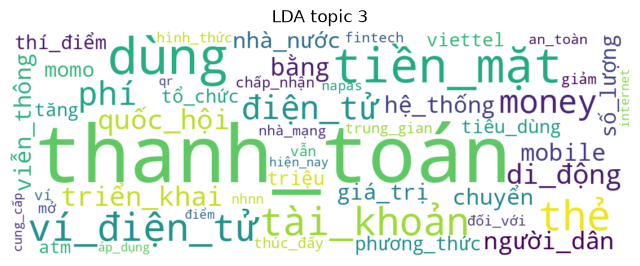

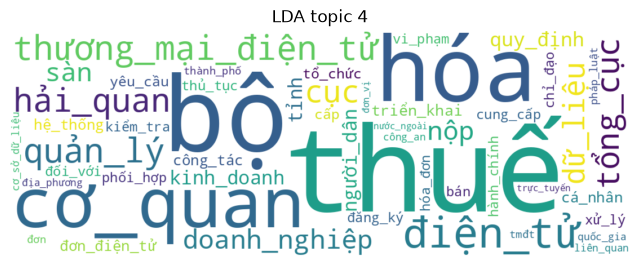

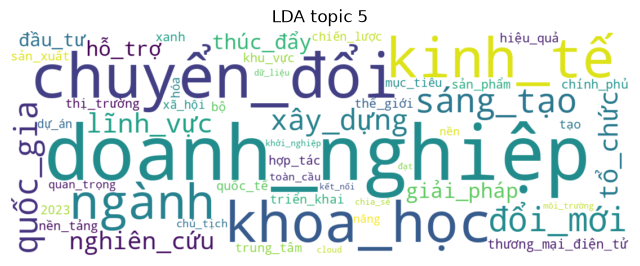

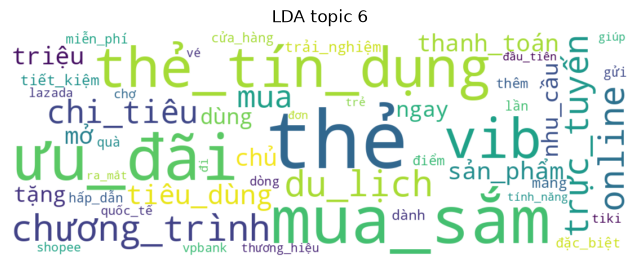

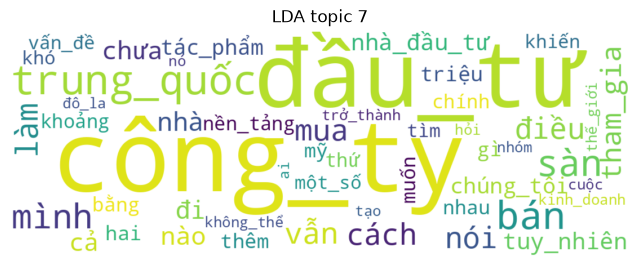

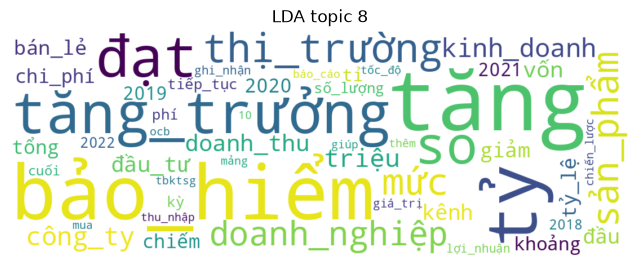

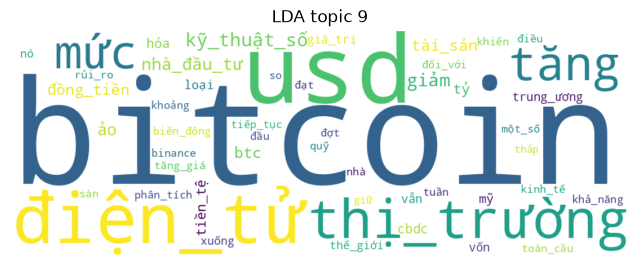

In [7]:
from wordcloud import WordCloud
# Inline PNG output only; no external image files.
for i in range(best_k):
    freqs=dict(lda_models[best_k].show_topic(i,topn=50))
    fig,ax=plt.subplots(figsize=(8,3))
    wc=WordCloud(width=1100,height=400,background_color='white',collocations=False).generate_from_frequencies(freqs)
    ax.imshow(wc,interpolation='bilinear');ax.axis('off');ax.set_title(f'LDA topic {i}')
    display(fig);plt.close(fig)

In [8]:
import pyLDAvis, pyLDAvis.gensim_models
prepared=pyLDAvis.gensim_models.prepare(lda_models[best_k],corpus,dictionary,sort_topics=False,n_jobs=1)
display(HTML(pyLDAvis.prepared_data_to_html(prepared)))
print('Interactive pyLDAvis HTML is embedded above; no separate HTML file.')

Interactive pyLDAvis HTML is embedded above; no separate HTML file.


## 3. Pinned CPU embeddings with 500-document checkpoints

The model card specifies a 768-dimensional embedding and 8,192-token default maximum. We leave `max_seq_length` unchanged. The model revision is pinned; its trusted custom implementation was checked during the smoke test. Transformers 5 incorrectly leaves its nonpersistent `position_ids` and rotary-position buffers uninitialized and no longer supplies `get_extended_attention_mask` to this custom class. The two repairs below restore the class's original intended behavior without changing model weights or text length. This compatibility detail must be revisited when package versions change. Checkpoints are `.npy` under `~/.cache/fintech_topic_8017` and are temporary runtime artifacts, not project deliverables.

In [9]:
import torch
from sentence_transformers import SentenceTransformer
torch.set_num_threads(4)
os.environ['HF_HUB_OFFLINE']='1'
encoder=SentenceTransformer(MODEL_ID,revision=MODEL_REVISION,device='cpu',trust_remote_code=True)
assert encoder.max_seq_length==8192
repaired=[]
for module in encoder.modules():
    if hasattr(module,'position_ids') and isinstance(module.position_ids,torch.Tensor) and module.position_ids.ndim==1:
        n=module.position_ids.numel()
        module.register_buffer('position_ids',torch.arange(n,device=module.position_ids.device),persistent=False)
        repaired.append(n)
def extended_attention_mask(self,mask,input_shape,device=None,dtype=None):
    dtype=dtype or next(self.parameters()).dtype
    return (1.0-mask[:,None,None,:].to(dtype=dtype))*torch.finfo(dtype).min
embedding_layer=encoder[0].auto_model.embeddings
model_config=encoder[0].auto_model.config
rotary_class=type(embedding_layer.rotary_emb)
embedding_layer.rotary_emb=rotary_class(
    dim=model_config.hidden_size//model_config.num_attention_heads,
    max_position_embeddings=model_config.max_position_embeddings,
    base=model_config.rope_theta,
    scaling_factor=model_config.rope_scaling['factor'],
    mixed_b=model_config.rope_scaling.get('mixed_b'),
)
assert torch.allclose(embedding_layer.rotary_emb.cos_cached[0],torch.ones_like(embedding_layer.rotary_emb.cos_cached[0]))
assert torch.allclose(embedding_layer.rotary_emb.sin_cached[0],torch.zeros_like(embedding_layer.rotary_emb.sin_cached[0]))
encoder[0].auto_model.get_extended_attention_mask=types.MethodType(extended_attention_mask,encoder[0].auto_model)
assert repaired and (encoder[0].auto_model.embeddings.position_ids[:20]==torch.arange(20)).all()
smoke=encoder.encode(articles.text.head(4).tolist(),batch_size=4,device='cpu',normalize_embeddings=True,show_progress_bar=False)
assert smoke.shape==(4,768) and np.isfinite(smoke).all() and np.allclose(np.linalg.norm(smoke,axis=1),1,atol=1e-5)
print('Embedding smoke passed:',smoke.shape,'max_seq_length',encoder.max_seq_length)

Loading weights:   0%|          | 0/136 [00:00<?, ?it/s]

Embedding smoke passed: (4, 768) max_seq_length 8192


In [ ]:
from numpy.lib.format import open_memmap
embed_file=TMP/'embeddings.npy'; progress_file=TMP/'embedding_progress.json'
N=len(articles); DIM=768
if embed_file.exists() and progress_file.exists():
    progress=json.loads(progress_file.read_text())
    assert progress['model_revision']==MODEL_REVISION and progress['n_documents']==N and progress['corpus_sha']==CORPUS_SHA
    done=int(progress['done'])
    embeddings=open_memmap(embed_file,mode='r+',dtype='float32',shape=(N,DIM))
else:
    done=0;embeddings=open_memmap(embed_file,mode='w+',dtype='float32',shape=(N,DIM))
print('Resuming at',done,'of',N,flush=True)
start=time.time()
for i in range(done,N,4):
    batch=articles.text.iloc[i:min(i+4,N)].tolist()
    embeddings[i:i+len(batch)]=encoder.encode(batch,batch_size=4,device='cpu',normalize_embeddings=True,show_progress_bar=False)
    completed=i+len(batch)
    if completed%500<4 or completed==N:
        embeddings.flush()
        progress_file.write_text(json.dumps({'done':completed,'model_revision':MODEL_REVISION,'n_documents':N,'corpus_sha':CORPUS_SHA}))
        print('Embedded',completed,'/',N,'elapsed hours',round((time.time()-start)/3600,2),flush=True)
assert np.isfinite(embeddings).all()
print('Embeddings complete; shape',embeddings.shape,'norm range',np.linalg.norm(embeddings,axis=1).min(),np.linalg.norm(embeddings,axis=1).max())
del encoder;gc.collect()

## 4. BERTopic grid and stability

All 12 requested combinations reuse the same normalized embeddings. UMAP seed 42 is fixed for the grid. The selection rule is highest finite c_v among solutions with at least two nonoutlier topics, breaking ties toward lower outlier rate and fewer topics. This is a diagnostic choice, not a claim that the selected topics are substantively correct. Seeds 123 and 456 then test stability of the selected UMAP/HDBSCAN configuration.

In [ ]:
from bertopic import BERTopic
from umap import UMAP
from hdbscan import HDBSCAN
from bertopic.vectorizers import ClassTfidfTransformer
from itertools import product
def build_bertopic(nn,cs,ms,seed):
    reducer=UMAP(n_neighbors=nn,n_components=5,min_dist=0.0,metric='cosine',low_memory=True,random_state=seed,n_jobs=1)
    clusterer=HDBSCAN(min_cluster_size=cs,min_samples=ms,metric='euclidean',cluster_selection_method='eom',prediction_data=False,core_dist_n_jobs=1)
    vectorizer=CountVectorizer(tokenizer=str.split,token_pattern=None,lowercase=False,ngram_range=(1,2),min_df=2,max_features=30000)
    return BERTopic(umap_model=reducer,hdbscan_model=clusterer,vectorizer_model=vectorizer,ctfidf_model=ClassTfidfTransformer(reduce_frequent_words=True),top_n_words=10,calculate_probabilities=False,representation_model=None,verbose=False)
def bertopic_words(model):
    return [[w for w,_ in model.get_topic(t)[:10]] for t in sorted(model.get_topics()) if t!=-1 and model.get_topic(t)]
def ctfidf_similarity(model):
    topics=sorted(t for t in model.get_topics() if t!=-1)
    if len(topics)<2:return np.nan
    # BERTopic topic rows are sorted by topic ID; -1, when present, is first.
    matrix=model.c_tf_idf_[-len(topics):]
    sim=cosine_similarity(matrix)
    return float(sim[np.triu_indices(len(topics),1)].mean())
bertopic_rows=[]; best_model=None;best_topics=None;best_key=None;best_score=None
for nn,cs,ms in product([15,30],[15,30,50],[5,10]):
    t0=time.time();checkpoint=TMP/f'bertopic_nn{nn}_cs{cs}_ms{ms}_seed42.pkl'
    if checkpoint.exists():
        with checkpoint.open('rb') as f:payload=pickle.load(f)
        assert payload['corpus_sha']==CORPUS_SHA and payload['model_revision']==MODEL_REVISION
        m=payload['model'];assignments=payload['assignments'];row=payload['row']
        print('BERTopic restored',nn,cs,ms,flush=True)
    else:
        m=build_bertopic(nn,cs,ms,42)
        assignments,_=m.fit_transform(segmented,embeddings=np.asarray(embeddings))
        words=bertopic_words(m)
        coh=coherence_scores(words) if len(words)>=2 else {'c_v':np.nan,'c_npmi':np.nan}
        outlier=float(np.mean(np.array(assignments)==-1))
        row={'n_neighbors':nn,'min_cluster_size':cs,'min_samples':ms,'n_topics':len(words),'outlier_rate':outlier,**coh,'topic_diversity':topic_diversity(words),'mean_ctfidf_similarity':ctfidf_similarity(m),'minutes':(time.time()-t0)/60}
        tmp=checkpoint.with_suffix('.partial')
        with tmp.open('wb') as f:pickle.dump({'corpus_sha':CORPUS_SHA,'model_revision':MODEL_REVISION,'model':m,'assignments':assignments,'row':row},f,protocol=pickle.HIGHEST_PROTOCOL)
        tmp.replace(checkpoint)
        print('BERTopic fitted',row,flush=True)
    bertopic_rows.append(row)
    key=(row['c_v'] if np.isfinite(row['c_v']) else -np.inf,-row['outlier_rate'],-row['n_topics'])
    if best_score is None or key>best_score:
        old=best_model
        best_score=key;best_model=m;best_topics=np.array(assignments);best_key=(nn,cs,ms)
        if old is not None:del old
    else:
        del m
    gc.collect()
bertopic_scores=pd.DataFrame(bertopic_rows).sort_values(['c_v','outlier_rate','n_topics'],ascending=[False,True,True])
assert best_model is not None and np.isfinite(best_score[0])
display(bertopic_scores)
print('Selected BERTopic',best_key)

In [ ]:
best_words=bertopic_words(best_model)
bert_seed_words={42:best_words}
for seed in [123,456]:
    checkpoint=TMP/f'bertopic_nn{best_key[0]}_cs{best_key[1]}_ms{best_key[2]}_seed{seed}.json'
    if checkpoint.exists():
        payload=json.loads(checkpoint.read_text());assert payload['corpus_sha']==CORPUS_SHA
        bert_seed_words[seed]=payload['words'];outlier=payload['outlier_rate']
    else:
        m=build_bertopic(*best_key,seed)
        labels,_=m.fit_transform(segmented,embeddings=np.asarray(embeddings))
        bert_seed_words[seed]=bertopic_words(m)
        outlier=float(np.mean(np.array(labels)==-1))
        checkpoint.write_text(json.dumps({'corpus_sha':CORPUS_SHA,'words':bert_seed_words[seed],'outlier_rate':outlier}))
        del m;gc.collect()
    print('Seed',seed,'topics',len(bert_seed_words[seed]),'outlier rate',round(outlier,4),flush=True)
bertopic_stability=pd.DataFrame([{'seed_a':a,'seed_b':b,'matched_jaccard':stability(bert_seed_words[a],bert_seed_words[b])} for a,b in [(42,123),(42,456),(123,456)]])
display(bertopic_stability)
display(best_model.get_topic_info().head(30))

In [ ]:
# URL-linked assignments and representative documents for interpretation; table output remains in notebook.
assignment_table=articles[['url','title','pub_date']].copy()
assignment_table['topic']=best_topics
assignment_table['is_outlier']=assignment_table.topic.eq(-1)
frequency=assignment_table.groupby('topic').size().rename('n_articles').reset_index().sort_values('n_articles',ascending=False)
display(frequency)
representatives=[]
for topic in sorted(t for t in best_model.get_topics() if t!=-1):
    docs=best_model.get_representative_docs(topic) or []
    for rank,doc in enumerate(docs[:3],1):
        matches=np.flatnonzero(np.array(segmented,dtype=object)==doc)
        representatives.append({'topic':topic,'rank':rank,'url':articles.url.iloc[matches[0]] if len(matches) else '', 'title':articles.title.iloc[matches[0]] if len(matches) else '', 'excerpt':doc[:350]})
display(pd.DataFrame(representatives).head(60))

## 5. BERTopic visualizations

Interactive Plotly HTML is embedded as notebook output. The document map uses a 20% sample for browser responsiveness; topic fitting still used all 8,017 articles. Temporal binning uses 12 bins from `pub_date`. A failed optional visualization is reported inline and does not invalidate fitted topics.

In [ ]:
def show_plot(name,fn):
    try:
        fig=fn()
        display(HTML(fig.to_html(full_html=False,include_plotlyjs='cdn')))
        print(name,'rendered')
    except Exception as exc:
        print(name,'unavailable:',type(exc).__name__,str(exc)[:500])
show_plot('Intertopic distance map',lambda:best_model.visualize_topics())
show_plot('Hierarchical clustering',lambda:best_model.visualize_hierarchy())
show_plot('Top word barchart',lambda:best_model.visualize_barchart(top_n_topics=min(20,len(best_words)),n_words=10))
show_plot('Topic similarity heatmap',lambda:best_model.visualize_heatmap(top_n_topics=min(30,len(best_words))))

In [ ]:
show_plot('Document visualization',lambda:best_model.visualize_documents(segmented,embeddings=np.asarray(embeddings),sample=0.2))
valid=articles.pub_date_parsed.notna().to_numpy()
if valid.any():
    temporal=best_model.topics_over_time([segmented[i] for i in np.flatnonzero(valid)],timestamps=articles.loc[valid,'pub_date_parsed'].dt.tz_localize(None).tolist(),topics=best_topics[valid].tolist(),nr_bins=12)
    display(temporal.head(20))
    show_plot('Topics over time',lambda:best_model.visualize_topics_over_time(temporal))

## 6. Interpretation and reproducibility summary

Read topic words and representative article excerpts before naming topics. Topic diversity and c-TF-IDF similarity can reveal overlap, while outlier rate records HDBSCAN's unassigned documents. Coherence and stability are only proxies for interpretability. LDA and BERTopic use different generative assumptions and topic-count mechanisms, so the highest score across methods is not a universal winner. The URL assignment table above can be copied directly from the notebook for human review without creating extra project files.

In [ ]:
summary=pd.DataFrame([
 {'method':'LDA','selected_configuration':f'K={best_k}','c_v':float(lda_scores.set_index('num_topics').loc[best_k,'c_v']),'c_npmi':float(lda_scores.set_index('num_topics').loc[best_k,'c_npmi']),'diversity':float(lda_scores.set_index('num_topics').loc[best_k,'topic_diversity']),'outlier_rate':0.0,'mean_seed_stability':float(lda_stability.matched_jaccard.mean())},
 {'method':'BERTopic','selected_configuration':f'UMAP neighbors={best_key[0]}; HDBSCAN cluster={best_key[1]}, samples={best_key[2]}','c_v':float(bertopic_scores.iloc[0].c_v),'c_npmi':float(bertopic_scores.iloc[0].c_npmi),'diversity':float(bertopic_scores.iloc[0].topic_diversity),'outlier_rate':float(bertopic_scores.iloc[0].outlier_rate),'mean_seed_stability':float(bertopic_stability.matched_jaccard.mean())}
])
display(summary)
print('Completed',pd.Timestamp.now().isoformat())